In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Napomena
# =========================================================

In [3]:
# FT i IFT (numericka aproksimacija Fourierove transformacije)
# se nalaze u sis modulu -> sis.FT, sis.IFT  

def FT(x, t, w, ts):
    """Numericka aproksimacija Fourierove transformacije."""
    c = np.zeros(len(w), dtype=complex)
    for k, wk in enumerate(w):
        c[k] = ts * np.sum(x * np.exp(-1j * wk * t))
    return c


def IFT(F, w, t, ws):
    """Numericka aproksimacija inverzne Fourierove transformacije."""
    f = np.zeros(len(t), dtype=complex)
    for k, tk in enumerate(t):
        f[k] = ws / (2 * np.pi) * np.sum(F * np.exp(1j * w * tk))
    return f

In [4]:
# =========================================================
# Kod 7.1 - Zvjezdasta funkcija
# =========================================================

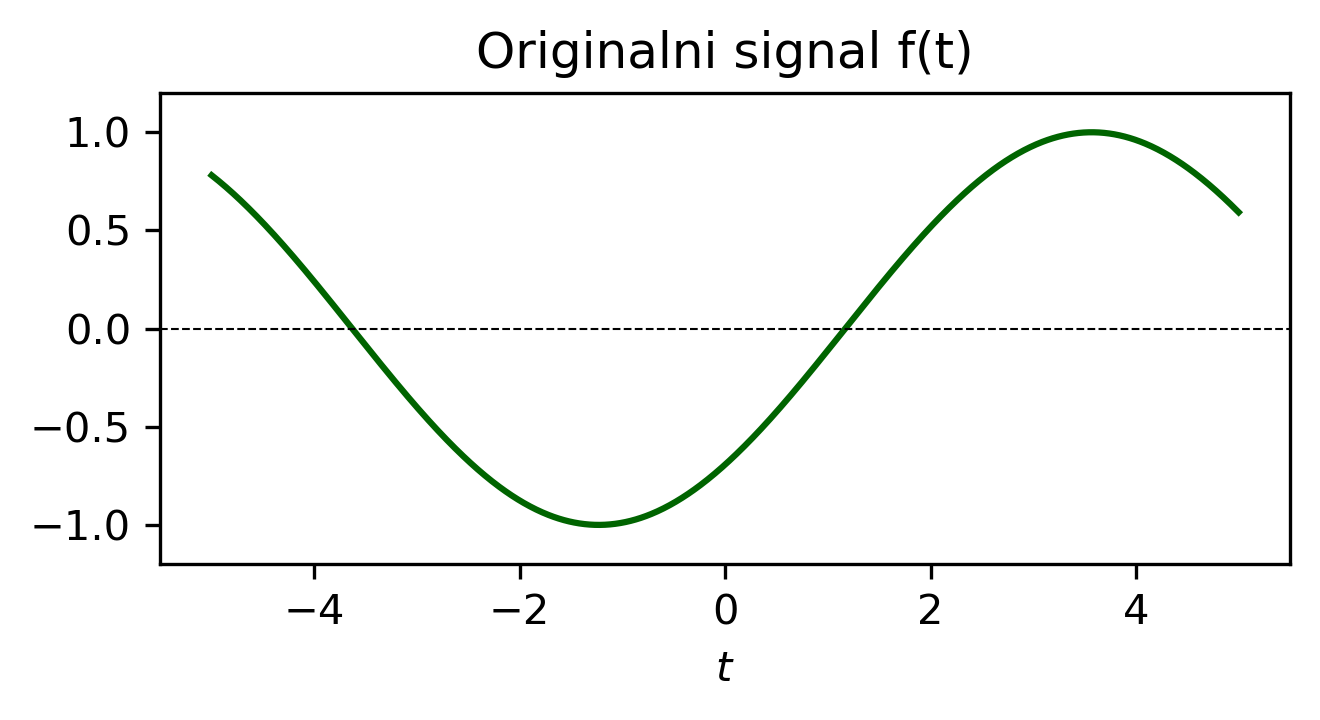

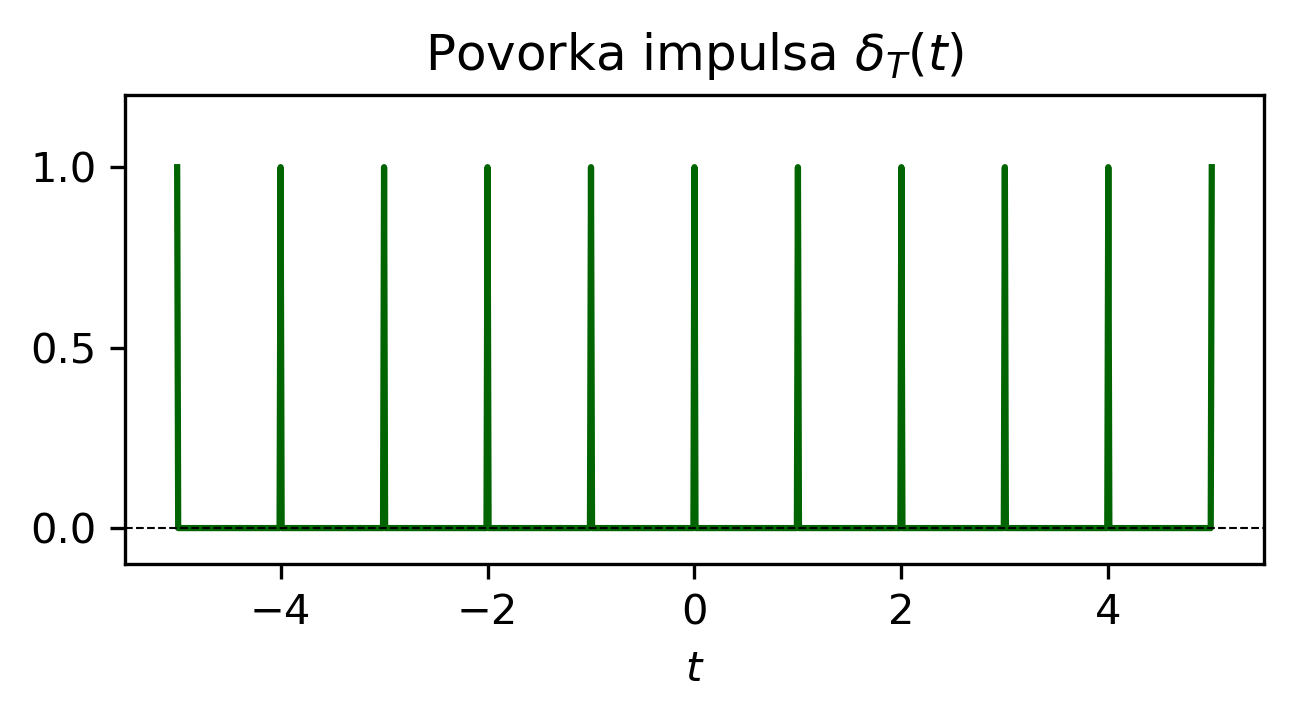

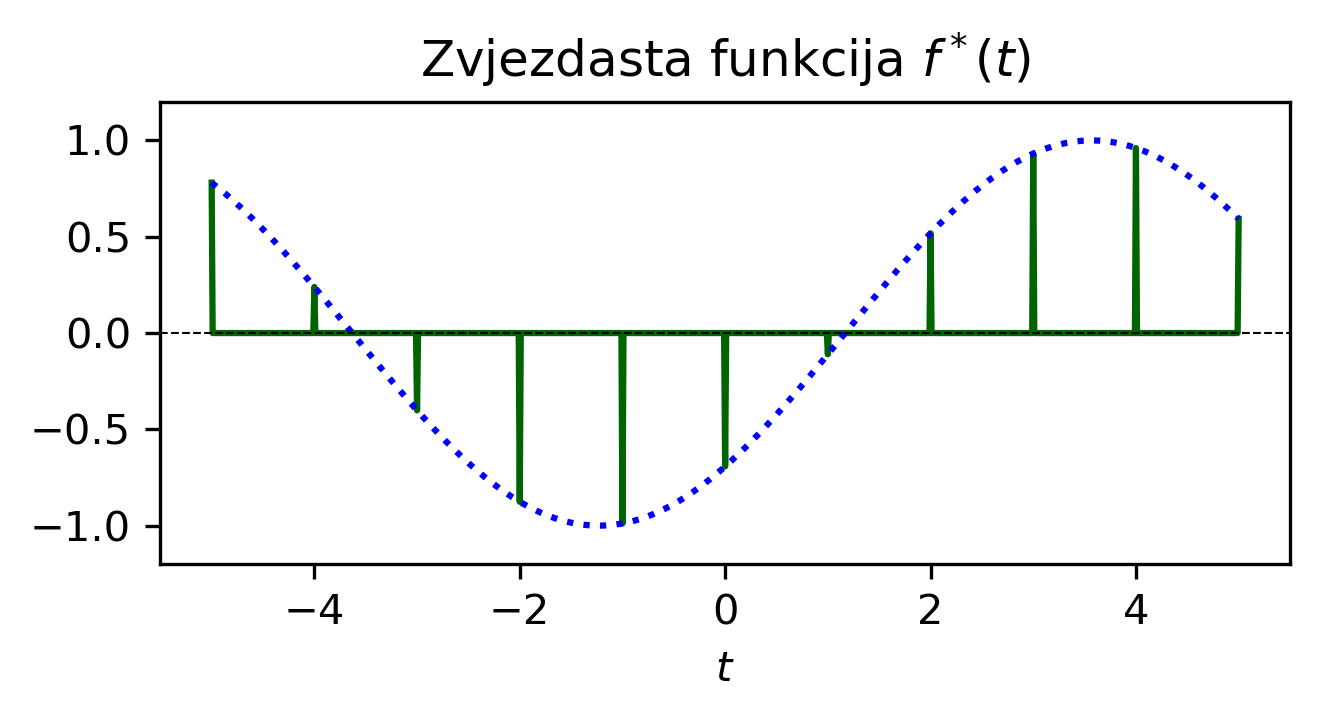

In [5]:
ts = 0.01   # korak diskretizacije "kontinualnog" signala
T  = 1.0    # period uzorkovanja (interval izmedju impulsa)

t = np.arange(-5, 5 + ts, ts)

# originalni signal - predstavljen kao diskretan sa korakom ts
x = np.sin(t * (np.pi / 4.8) - 0.765)

# povorka impulsa: jedinicni impulsi na svakih T sekundi
korak_s = int(T / ts)
y = np.zeros(len(t))
y[::korak_s] = 1

# zvjezdasta funkcija = proizvod signala i povorke impulsa
z = y * x

sis.dijagram(t, x, 
             ylim=(-1.2, 1.2),
             naslov=r'Originalni signal f(t)'),

sis.dijagram(t, x=y, 
             ylim=(-0.1, 1.2),
             naslov=r'Povorka impulsa $\delta_T(t)$'),

sis.dijagram(serije=[dict(t=t, x=z), dict(t=t, x=x, stil='b:')],
         ylim=(-1.2, 1.2), naslov=r'Zvjezdasta funkcija $f^*(t)$')

In [6]:
# =========================================================
# Kod 7.2 - Spektar zvjezdaste funkcije
# =========================================================

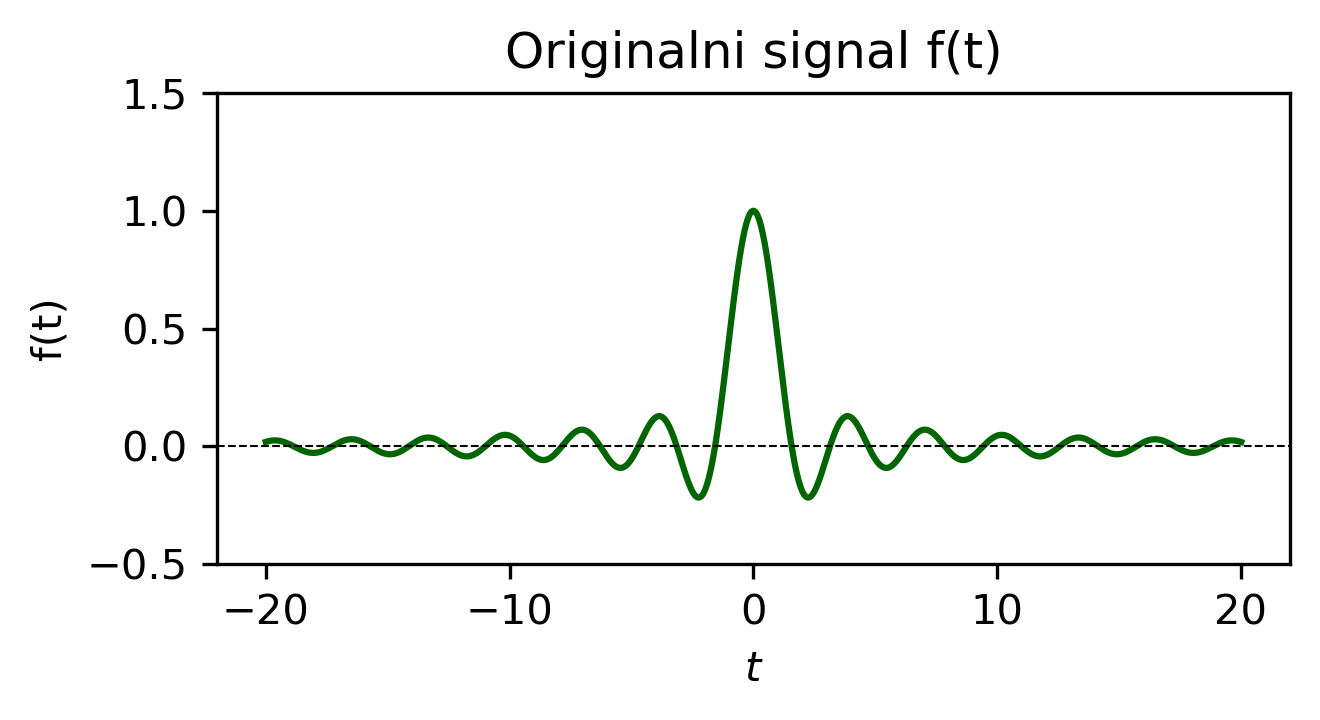

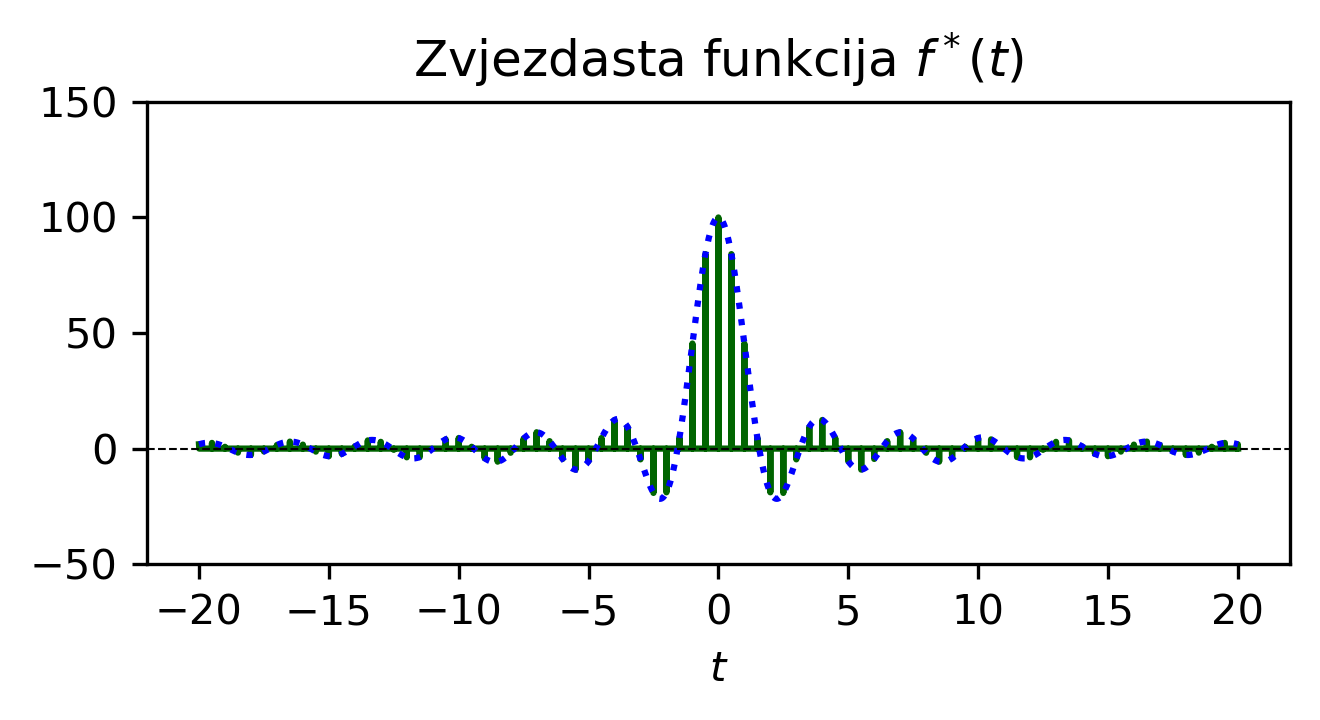

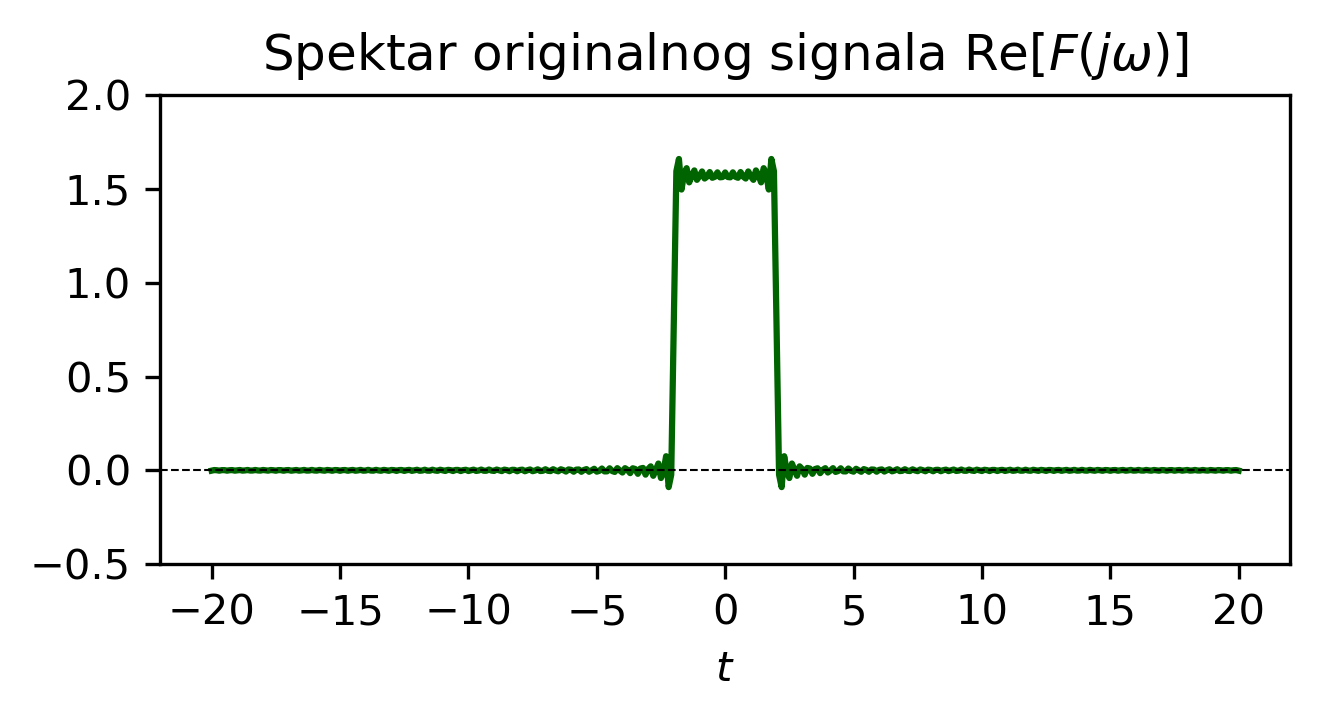

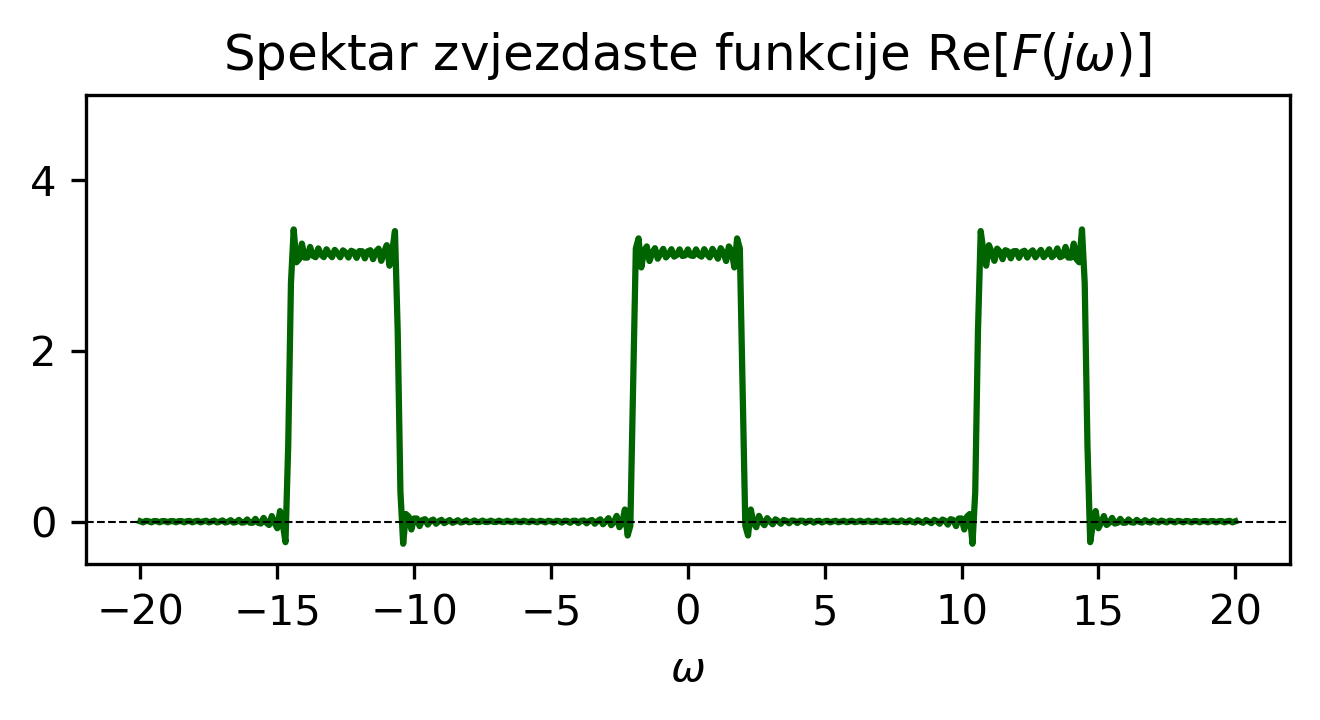

In [7]:
ts  = 0.01    # korak diskretizacije "kontinualnog" signala
ws  = 0.1    # korak diskretizacije frekventne ose
gra = 20
a   = 2.0
T   = 0.5    # period uzorkovanja

t = np.arange(-gra, gra + ts, ts)
w = np.arange(-gra, gra + ws, ws)

# originalni signal Sa(at) - predstavljen kao diskretan, korak ts
x = np.sinc(a * t / np.pi)

# povorka impulsa: visina 1/ts (povrsina = 1), period uzorkovanja T
korak_s = int(T / ts)
y = np.zeros(len(t))
y[::korak_s] = 1 / ts

# zvjezdasta funkcija
z = x * y

sis.dijagram(t, x, 
             ylim=(-0.5, 1.5),
             y_labela='f(t)', naslov='Originalni signal f(t)')

sis.dijagram(serije=[dict(t=t, x=z), dict(t=t, x=x/ts, stil='b:')],
             ylim=(-50, 150), naslov=r'Zvjezdasta funkcija $f^*(t)$')

# racunanje spektra - FT se primjenjuje na "kontinualne" reprezentacije
cx = sis.FT(x, t, w, ts)
cz = sis.FT(z, t, w, ts)

sis.dijagram(w, np.real(cx), 
             ylim=(-0.5, 2), 
             naslov=r'Spektar originalnog signala $\mathrm{Re}[F(j\omega)]$') 

sis.dijagram(w, np.real(cz), 
             ylim=(-0.5, 5),
             x_labela=r'$\omega$', 
             naslov=r'Spektar zvjezdaste funkcije $\mathrm{Re}[F(j\omega)]$')

In [8]:
# =========================================================
# Kod 7.3 - Izvedena periodicka funkcija (sa mogucim preklapanjem)
# =========================================================

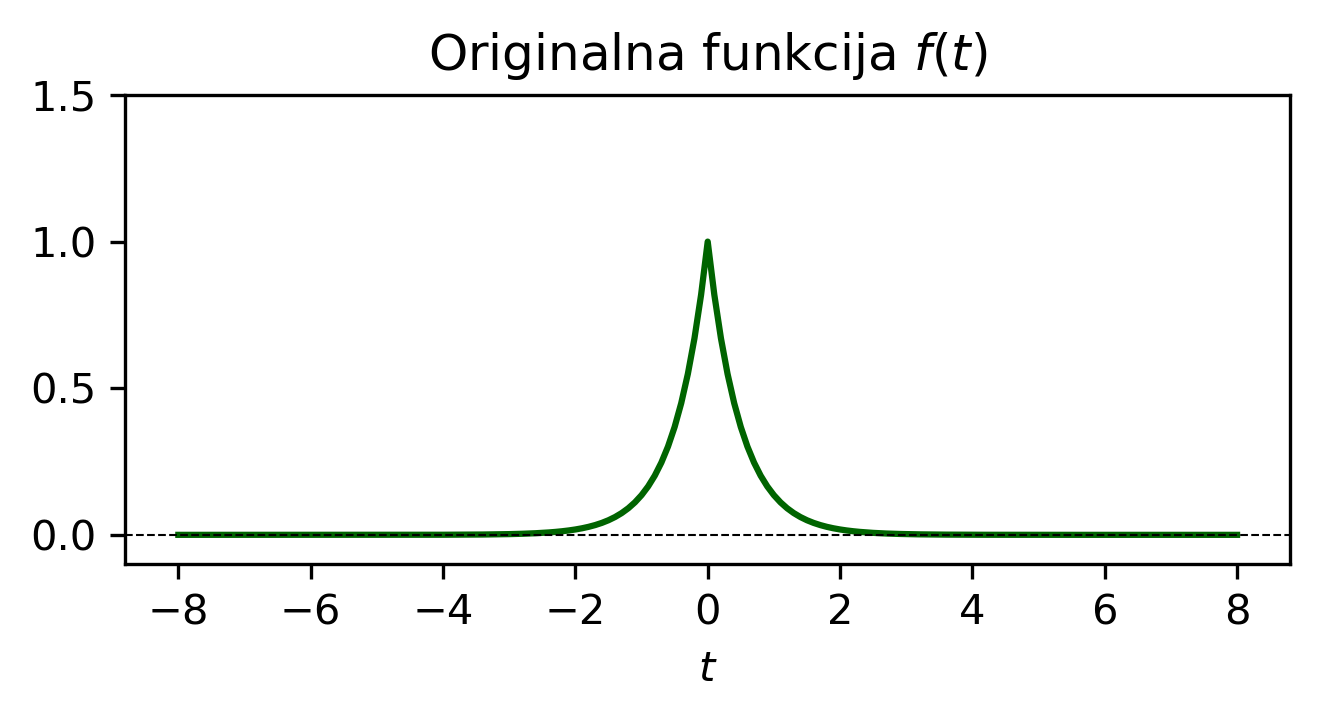

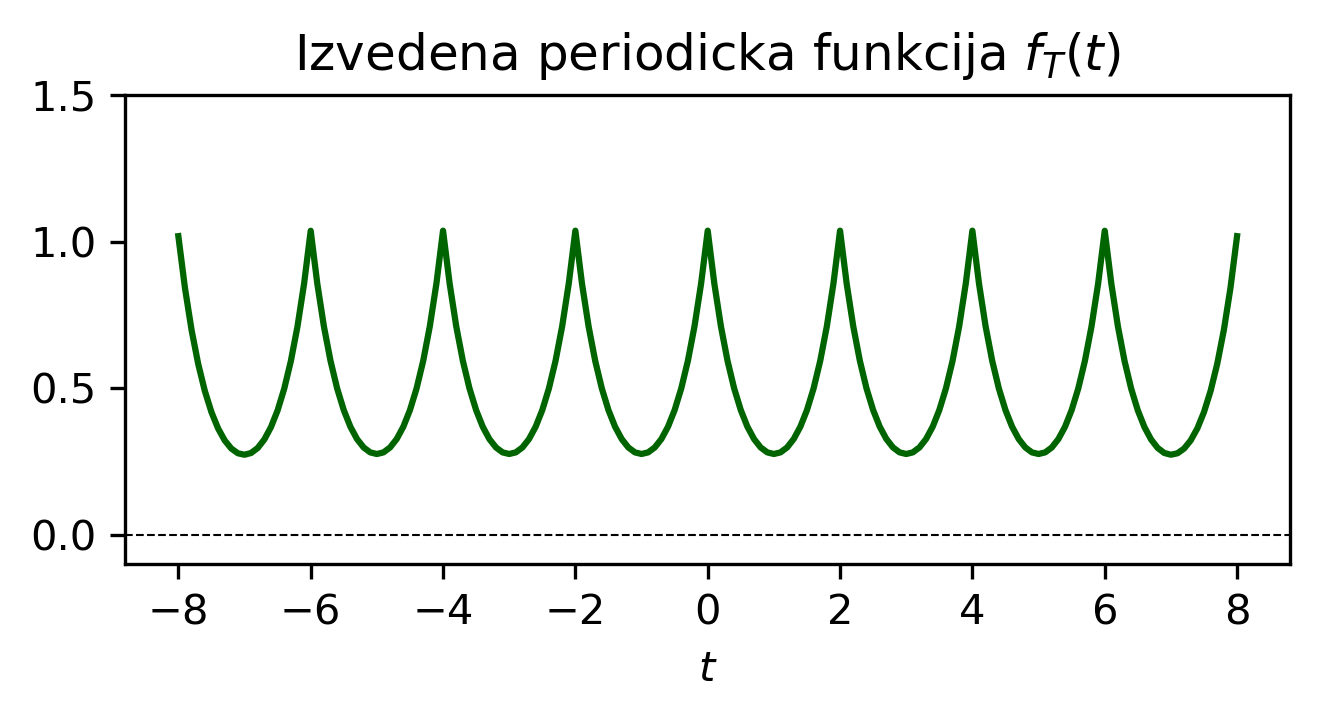

In [9]:
ts   = 0.1   # korak diskretizacije
T    = 2.0   # period izvedene periodicke funkcije
Nper = 4     # broj perioda s obje strane

# cijela vremenska baza
t = np.arange(-Nper * T, Nper * T + ts, ts)

# originalna funkcija f(t) definirana na cijelom intervalu
f = np.exp(-np.abs(2 * t))

# periodicko ponavljanje: fT = suma f(t - kT)
fT = np.zeros(len(t))
for k in range(-Nper, Nper + 1):
    fT += np.exp(-np.abs(2 * (t - k * T)))

sis.dijagram(t, f, 
             ylim=(-0.1, 1.5), 
             naslov='Originalna funkcija $f(t)$')


sis.dijagram(t, fT, 
             ylim=(-0.1, 1.5), 
             naslov='Izvedena periodicka funkcija $f_T(t)$') 